# 🧠 AI Brain: Banking Intent Classifier

This notebook builds a simple "AI brain" that can **understand** a customer message and **respond** to it.

**Pipeline:** load data → clean text → turn text into numbers (TF-IDF) → train a classifier → tune a confidence threshold → test once on unseen data → build replies → save the model for a Streamlit app.

**Dataset:** Banking77 (`train.csv` and `test.csv`), customer-service questions labeled with 77 intents.

**Runtime:** CPU is enough. No GPU needed.

> Run the cells in order, top to bottom. If you restart the runtime, re-run everything from Step 1.

## Step 1: Import the tools

We load the libraries we need:
- **pandas / NumPy** to work with tables and numbers
- **matplotlib** to draw charts
- **scikit-learn** for the machine-learning parts: the text vectorizer, the models, and the evaluation tools
- **joblib** to save the trained model to a file
- **re / random** for text cleaning and picking random replies

In [ ]:
import re, glob, random, joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

## Step 2: Connect Google Drive

Colab's storage is temporary, so our data lives in Google Drive. This cell mounts Drive and checks that the folder **Banking 77 file** exists and contains `train.csv` and `test.csv`.

If it says the folder doesn't exist, the name is slightly different. Print `os.listdir("/content/drive/MyDrive")` to see the exact name.

In [ ]:
import os
from google.colab import drive
drive.mount('/content/drive')

FOLDER = "/content/drive/MyDrive/Banking 77 file"
print("Folder exists:", os.path.exists(FOLDER))
print("Files inside:", os.listdir(FOLDER))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Folder exists: True
Files inside: ['train.csv', 'test.csv']


## Step 3: Load the data

We read both CSV files into pandas tables (DataFrames) and look at their size and column names.

- **train.csv:** the examples the model learns from
- **test.csv:** examples kept locked away until the very end, so we can measure how well the model handles messages it has never seen

`train.head()` shows the first few rows so we can see what the data looks like.

In [ ]:
TRAIN_PATH = f"/content/drive/MyDrive/Banking 77 file/train.csv"
TEST_PATH  = f"/content/drive/MyDrive/Banking 77 file/test.csv"

train = pd.read_csv(TRAIN_PATH)
test  = pd.read_csv(TEST_PATH)
print("train:", train.shape, "| test:", test.shape)
print("train columns:", list(train.columns))
print("test columns: ", list(test.columns))
train.head()

train: (10003, 2) | test: (3080, 2)
train columns: ['text', 'category']
test columns:  ['text', 'category']


,text,category
0,I am still waiting on my card?,card_arrival
1,What can I do if my card still hasn't arrived ...,card_arrival
2,I have been waiting over a week. Is the card s...,card_arrival
3,Can I track my card while it is in the process...,card_arrival
4,"How do I know if I will get my card, or if it ...",card_arrival


## Step 4: Find the text and label columns

Different datasets name their columns differently, so this cell guesses:
- **Text column:** the column with the longest text on average
- **Label column:** the non-text column with the fewest distinct values (the intent categories)

It prints what it chose. If the guess is wrong, uncomment the override line and type the correct names.

In [ ]:
obj_cols = train.select_dtypes("object").columns
TEXT_COL = max(obj_cols, key=lambda c: train[c].astype(str).str.len().mean())
candidates = [c for c in train.columns
              if c != TEXT_COL and train[c].nunique() < 0.5 * len(train)]
LABEL_COL = min(candidates, key=lambda c: train[c].nunique())

# If the guess is wrong, override here:
# TEXT_COL, LABEL_COL = "text", "category"

print("Text column :", TEXT_COL)
print("Label column:", LABEL_COL, "| classes:", train[LABEL_COL].nunique())

Text column : text
Label column: category | classes: 77


## Step 5: Clean the text

Models work better when similar sentences look the same. We:
1. **Remove empty rows and duplicates** so no example is counted twice
2. **Lowercase** everything, so "Card" and "card" match
3. **Strip punctuation** and extra spaces

The cleaned text goes in a new column called `clean`. The original is kept untouched.

We also check whether `test.csv` has labels. If it does, we can compute accuracy on it later.

In [ ]:
def clean(t):
    t = str(t).lower()
    t = re.sub(r"[^a-z0-9\s']", " ", t)
    return re.sub(r"\s+", " ", t).strip()

train = train.dropna(subset=[TEXT_COL, LABEL_COL]).drop_duplicates(subset=[TEXT_COL]).copy()
train["clean"] = train[TEXT_COL].apply(clean)

HAS_TEST_LABELS = LABEL_COL in test.columns
test = test.dropna(subset=[TEXT_COL] + ([LABEL_COL] if HAS_TEST_LABELS else [])).copy()
test["clean"] = test[TEXT_COL].apply(clean)

print("Clean train rows:", len(train), "| test rows:", len(test))
print("Test has labels:", HAS_TEST_LABELS)

Clean train rows: 10003 | test rows: 3080
Test has labels: True


## Step 6: Check class balance

We count how many examples each intent has and plot it.

**Why it matters:** if one intent has hundreds of examples and another has five, the model will favor the big one. Knowing this helps explain mistakes later.

Classes: 77 | min: 35 | max: 187


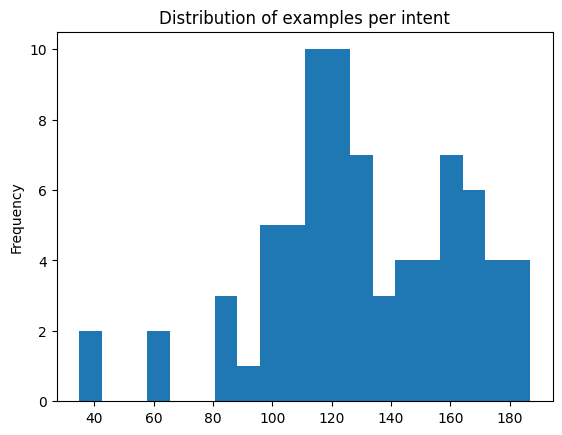

In [ ]:
counts = train[LABEL_COL].value_counts()
print("Classes:", len(counts), "| min:", counts.min(), "| max:", counts.max())
if len(counts) <= 30:
    counts.plot(kind="bar", title="Examples per intent")
else:
    counts.plot(kind="hist", bins=20, title="Distribution of examples per intent")
plt.show()

## Step 7: Create a validation set

We split the training data into:
- **85% train:** the model learns from this
- **15% validation:** used to compare models and tune settings

`test.csv` is **not touched** here. Keeping it sealed until the end gives an honest score, since we never tuned anything against it.

`stratify` keeps the same intent proportions in both parts.

In [ ]:
try:
    X_tr, X_val, y_tr, y_val = train_test_split(
        train["clean"], train[LABEL_COL], test_size=0.15,
        random_state=42, stratify=train[LABEL_COL])
except ValueError:   # some class has too few examples to stratify
    X_tr, X_val, y_tr, y_val = train_test_split(
        train["clean"], train[LABEL_COL], test_size=0.15, random_state=42)
print(len(X_tr), "train /", len(X_val), "validation")

8502 train / 1501 validation


## Step 8: Turn text into numbers (TF-IDF)

Machine-learning models can't read words, only numbers. **TF-IDF** converts each sentence into a list of numbers:
- **TF (term frequency):** how often a word appears in the sentence
- **IDF (inverse document frequency):** rare words count more, common words ("the", "my") count less

Settings used:
- `ngram_range=(1, 2)` looks at single words *and* word pairs, so "card arrival" is captured as a phrase
- `sublinear_tf=True` stops very repeated words from dominating

The vectorizer **learns its vocabulary from the training part only**, then is applied to validation. Fitting on validation data would leak information.

In [ ]:
vec = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)
Xtr_vec  = vec.fit_transform(X_tr)     # fit on train only
Xval_vec = vec.transform(X_val)
print("Vocabulary size:", len(vec.vocabulary_))

Vocabulary size: 21595


## Step 9: Train two models and compare

We train two simple, fast classifiers:
- **Logistic Regression:** learns a weight for each word per intent and picks the most likely intent
- **Multinomial Naive Bayes:** uses word-count probabilities; very quick and a strong baseline for text

Both are scored on the validation set, and the better one is kept as `best`.

In [ ]:
candidates = {
    "LogisticRegression": LogisticRegression(C=10, max_iter=1000),
    "NaiveBayes": MultinomialNB(alpha=0.1),
}
scores = {}
for name, m in candidates.items():
    m.fit(Xtr_vec, y_tr)
    scores[name] = accuracy_score(y_val, m.predict(Xval_vec))
    print(f"{name}: {scores[name]:.3f}")

best_name = max(scores, key=scores.get)
best = candidates[best_name]
print("\nBest:", best_name)

LogisticRegression: 0.885
NaiveBayes: 0.857

Best: LogisticRegression


## Step 10: Evaluate the model

- **Accuracy:** the share of validation messages predicted correctly
- **Classification report:** precision, recall and F1 for each intent. We list the **10 weakest** intents to see where it struggles
- **Confusion matrix:** shows which intents get mixed up. With 77 classes a full matrix is unreadable, so we print the **most confused pairs** (true intent → predicted intent)

Pairs that get confused are usually intents with very similar wording. That's a dataset property, not just a model flaw.

In [ ]:
pv = best.predict(Xval_vec)
print("Validation accuracy:", accuracy_score(y_val, pv))

rep = classification_report(y_val, pv, output_dict=True, zero_division=0)
per_class = (pd.DataFrame(rep).T
             .drop(["accuracy", "macro avg", "weighted avg"])
             .sort_values("f1-score"))
print("\nWeakest 10 classes:\n", per_class.head(10))

if len(best.classes_) <= 15:
    ConfusionMatrixDisplay.from_predictions(y_val, pv, xticks_rotation=45, cmap="Blues")
    plt.show()

cm = confusion_matrix(y_val, pv, labels=best.classes_)
np.fill_diagonal(cm, 0)
pairs = [(cm[i, j], best.classes_[i], best.classes_[j]) for i, j in zip(*np.nonzero(cm))]
print("\nMost confused pairs:")
for n, a, b in sorted(pairs, reverse=True)[:10]:
    print(f"  {n}x  true={a}  →  predicted={b}")

Validation accuracy: 0.8854097268487675

Weakest 10 classes:
                                          precision    recall  f1-score  \
top_up_failed                             0.823529  0.636364  0.717949   
compromised_card                          0.750000  0.692308  0.720000   
declined_card_payment                     0.678571  0.826087  0.745098   
pending_top_up                            0.772727  0.772727  0.772727   
pending_cash_withdrawal                   1.000000  0.636364  0.777778   
topping_up_by_card                        0.846154  0.733333  0.785714   
card_payment_not_recognised               0.750000  0.840000  0.792453   
balance_not_updated_after_bank_transfer   0.833333  0.769231  0.800000   
card_swallowed                            1.000000  0.666667  0.800000   
card_not_working                          0.777778  0.823529  0.800000   

                                         support  
top_up_failed                               22.0  
compromised_card     

## Step 11: Choose a confidence threshold

The model gives a probability for its top guess. If that probability is low, the bot shouldn't pretend to know.

This table shows, for each threshold:
- **answered:** the share of messages the bot would answer
- **accuracy when answered:** how often it is right on those

A higher threshold means more accurate answers but more "sorry, I didn't catch that" replies. Pick a balance and set `THRESHOLD` in the next step.

In [ ]:
probs = best.predict_proba(Xval_vec)
conf = probs.max(axis=1)
correct = best.classes_[probs.argmax(axis=1)] == y_val.values

print("threshold | answered | accuracy when answered")
for t in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    mask = conf >= t
    cov = mask.mean()
    acc = correct[mask].mean() if mask.any() else float("nan")
    print(f"   {t:.1f}    |  {cov:5.1%}  |  {acc:5.1%}")

threshold | answered | accuracy when answered
   0.1    |  98.9%  |  89.3%
   0.2    |  94.3%  |  91.7%
   0.3    |  90.3%  |  92.9%
   0.4    |  83.5%  |  94.5%
   0.5    |  76.9%  |  95.9%
   0.6    |  69.4%  |  97.4%
   0.7    |  61.4%  |  97.9%


## Step 12: Final model and the one-time test

Now that we've chosen the model type and settings:
1. **Retrain on all of the training data** (train + validation), since more data helps
2. **Test once on `test.csv`**, the data the model has never seen

This final accuracy is the honest number to report. Don't go back and tweak settings based on it, or it stops being a fair test.

If `test.csv` has no labels, predictions are saved to a CSV in Drive instead.

In [ ]:
THRESHOLD = 0.3   # set this from Cell 11

final_vec = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)
Xall = final_vec.fit_transform(train["clean"])
final_model = clone(best).fit(Xall, train[LABEL_COL])

Xtest = final_vec.transform(test["clean"])
test_preds = final_model.predict(Xtest)

if HAS_TEST_LABELS:
    print("FINAL TEST ACCURACY:", accuracy_score(test[LABEL_COL], test_preds))
else:
    out = test.copy()
    out["predicted_intent"] = test_preds
    out.drop(columns=["clean"]).to_csv("/content/drive/MyDrive/test_predictions.csv", index=False)
    print("test.csv has no labels, so predictions were saved to test_predictions.csv")

FINAL TEST ACCURACY: 0.8938311688311689


## Step 13: Build the response layer

A classifier only outputs a **label**, not a sentence. This step turns the label into a reply:
- `custom_replies` lets us write specific replies for chosen intents
- Any intent without a custom reply gets a friendly template
- `get_reply()` cleans the message, predicts the intent, checks the **confidence threshold**, and returns a reply, the intent, and the confidence
- Below the threshold, it returns the fallback message

The last lines test it, including an off-topic question that should trigger the fallback.

In [ ]:
def pretty(label):
    return str(label).replace("_", " ").lower()

# Optional: add hand-written replies. Keys must match your labels exactly.
custom_replies = {
    # "pricing": ["Our plans start at ₦X/month. Want the full list?"],
}

def make_reply(label):
    if label in custom_replies:
        return random.choice(custom_replies[label])
    return random.choice([
        f"It sounds like you're asking about '{pretty(label)}'. Let me help with that.",
        f"Got it, this is about '{pretty(label)}'. What would you like to know?",
    ])

def get_reply(text):
    v = final_vec.transform([clean(text)])
    p = final_model.predict_proba(v)[0]
    i = p.argmax()
    if p[i] < THRESHOLD:
        return "Sorry, I didn't catch that. Could you rephrase?", None, p[i]
    label = final_model.classes_[i]
    return make_reply(label), label, p[i]

for s in ["hello there", "what's the capital of France"]:
    reply, label, c = get_reply(s)
    print(f"{s!r} → {label} ({c:.2f}) → {reply}")

'hello there' → None (0.05) → Sorry, I didn't catch that. Could you rephrase?
"what's the capital of France" → None (0.07) → Sorry, I didn't catch that. Could you rephrase?


## Step 14: Chat with the brain

A simple loop: type a message, the bot answers, and it shows the detected intent and confidence in brackets. Type `quit` to stop.

This is the "understand and respond to conversations" part working end to end.

In [ ]:
print("Bot: Hi! Type 'quit' to exit.")
while True:
    user = input("You: ")
    if user.strip().lower() in ("quit", "exit"):
        print("Bot: Goodbye!")
        break
    reply, label, c = get_reply(user)
    print(f"Bot: {reply}   [{label}, {c:.2f}]")

Bot: Hi! Type 'quit' to exit.
You: Hello, I need to change my password
Bot: It sounds like you're asking about 'passcode forgotten'. Let me help with that.   [passcode_forgotten, 0.51]
You: Great. How do i change my passcode?
Bot: Got it, this is about 'passcode forgotten'. What would you like to know?   [passcode_forgotten, 0.89]
You: quit
Bot: Goodbye!


## Step 15: Save the brain

We bundle the **vectorizer**, the **model** and the **threshold** into one file, `ai_brain.joblib`, saved in Drive.

This is the file the Streamlit app loads, so it never needs to retrain. The scikit-learn version used here must match the version in the app's `requirements.txt`.

In [ ]:
joblib.dump({"vec": final_vec, "model": final_model, "threshold": THRESHOLD},
            "/content/drive/MyDrive/ai_brain.joblib")
print("Saved. Reload later with joblib.load(...)")

Saved. Reload later with joblib.load(...)


## Step 16: Natural replies with Gemini

Template replies are safe but robotic. Here we build a **hybrid brain**:
1. Our classifier detects the intent (fast, free, and we control it)
2. Gemini writes a natural reply using that intent as context

Setup:
- The API key is stored in Colab's **Secrets** tab as `GEMINI_API_KEY`, with notebook access on, so it never appears in the code
- `MODEL` holds the model name in one place, so it's easy to change if Google renames or retires it

If the API is unavailable or rate-limited, the classifier still works on its own.

In [ ]:
!pip install -q google-genai
from google import genai
from google.colab import userdata

client = genai.Client(api_key=userdata.get("GEMINI_API_KEY"))
MODEL = "gemini-3.8-flash"

def smart_reply(text):
    _, label, _ = get_reply(text)
    prompt = (f"You are a friendly support bot. The user's intent was classified as "
              f"'{label}'. Reply briefly and naturally to: {text}")
    return client.models.generate_content(model=MODEL, contents=prompt).text

print(smart_reply("How can i get repairs for my Phone screen?"))

I’d be happy to help you with that! You can get your screen repaired by scheduling an appointment at an authorized service center or submitting a mail-in repair request through our website. 

*(Just in case—if your phone was actually lost or stolen rather than damaged, let me know right away so we can help you secure your account!)*


## Summary

| Part | What we did |
|---|---|
| Data | Loaded Banking77 `train.csv` / `test.csv` from Drive |
| Preprocessing | Cleaned and deduplicated text |
| Features | TF-IDF with unigrams and bigrams |
| Models | Compared Logistic Regression and Naive Bayes |
| Evaluation | Validation accuracy, weakest intents, most confused pairs |
| Reliability | Tuned a confidence threshold with a fallback reply |
| Final test | Scored once on the unseen `test.csv` |
| Deployment | Saved `ai_brain.joblib` for the Streamlit app |

**Limitations:** matches words rather than meaning, has no conversation memory, and only knows the 77 banking intents.

**Next steps:** sentence embeddings or a fine-tuned BERT model, conversation memory, and out-of-scope training data for a stronger fallback.